In [1]:
# Assignment 8: Sentiment Analysis using LSTM

import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

keras.utils.set_random_seed(42)

import warnings
warnings.filterwarnings("ignore")

In [2]:
records = []

with gzip.open(r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-8-Sentiment-Analysis-LSTM\reviews_Automotive_5.json.gz", "rt", encoding="utf-8") as file:
    for line in file:
        review = json.loads(line)

        records.append({
            "rating": review.get("overall"),
            "summary": review.get("summary", ""),
            "text": review.get("reviewText", "")
        })

df = pd.DataFrame(records)

print("Reviews loaded:", df.shape[0])
df.head()

Reviews loaded: 20473


,rating,summary,text
0,5.0,Work Well - Should Have Bought Longer Ones,I needed a set of jumper cables for my new car...
1,4.0,Okay long cables,"These long cables work fine for my truck, but ..."
2,5.0,Looks and feels heavy Duty,Can't comment much on these since they have no...
3,5.0,Excellent choice for Jumper Cables!!!,I absolutley love Amazon!!! For the price of ...
4,5.0,"Excellent, High Quality Starter Cables",I purchased the 12' feet long cable set and th...


Rating distribution:
rating
1.0      542
2.0      606
3.0     1430
4.0     3967
5.0    13928
Name: count, dtype: int64


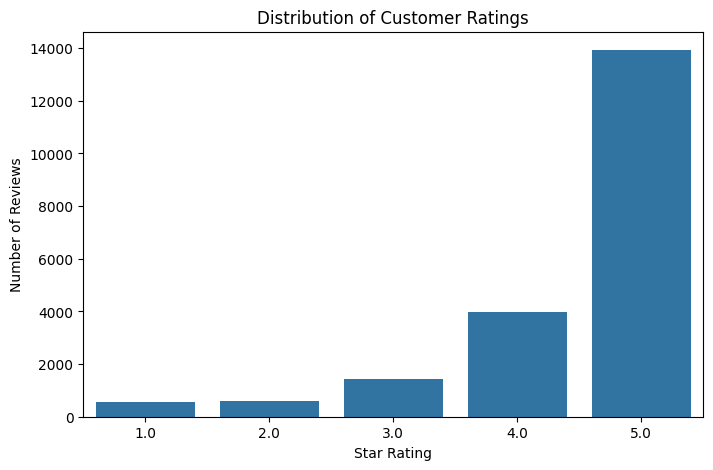

In [3]:
print("Rating distribution:")
print(df["rating"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating"
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.show()

In [4]:
# Three star reviews are ambiguous, so only clearly positive and
# clearly negative feedback is used
df = df[df["rating"] != 3]

df = df[df["text"].str.strip() != ""]

df["sentiment"] = (df["rating"] >= 4).astype(int)

print("Reviews used:", df.shape[0])
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())
print("\nPositive share: %.1f percent" % (df["sentiment"].mean() * 100))

Reviews used: 19037

Sentiment distribution:
sentiment
1    17890
0     1147
Name: count, dtype: int64

Positive share: 94.0 percent


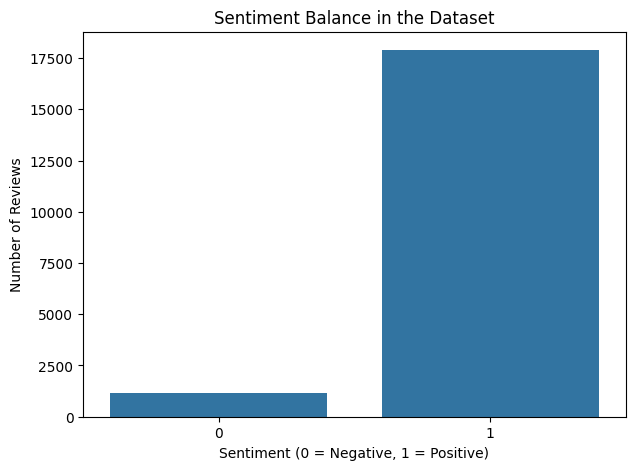

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Sentiment Balance in the Dataset")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.show()

In [6]:
# Positive reviews outnumber negative ones by roughly fifteen to one.
# Some of the positive reviews are set aside so that the model sees
# enough negative feedback to learn from.
negative_reviews = df[df["sentiment"] == 0]

positive_reviews = df[df["sentiment"] == 1].sample(
    n=len(negative_reviews) * 2,
    random_state=42
)

df = pd.concat([negative_reviews, positive_reviews])
df = df.sample(frac=1, random_state=42)

print("Reviews after balancing:", df.shape[0])
print(df["sentiment"].value_counts())

Reviews after balancing: 3441
sentiment
1    2294
0    1147
Name: count, dtype: int64


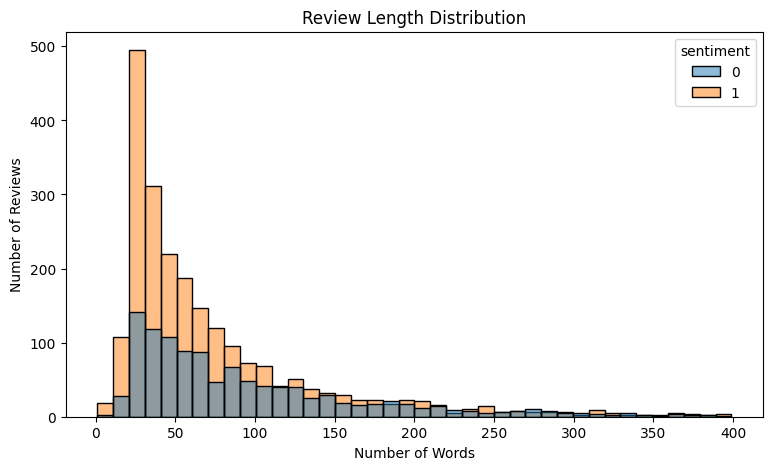

count    3441.0
mean       89.9
std       102.7
min         1.0
25%        32.0
50%        57.0
75%       107.0
max      1324.0
Name: word_count, dtype: float64


In [7]:
df["word_count"] = df["text"].str.split().str.len()

plt.figure(figsize=(9, 5))

sns.histplot(
    df[df["word_count"] < 400],
    x="word_count",
    hue="sentiment",
    bins=40
)

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

print(df["word_count"].describe().round(1))

In [8]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["sentiment"]
)

print("Training reviews:", train_df.shape[0])
print("Testing reviews :", test_df.shape[0])

Training reviews: 2752
Testing reviews : 689


In [9]:
VOCABULARY_SIZE = 10000
SEQUENCE_LENGTH = 150

vectorizer = layers.TextVectorization(
    max_tokens=VOCABULARY_SIZE,
    output_sequence_length=SEQUENCE_LENGTH
)

vectorizer.adapt(train_df["text"].values)

print("Vocabulary size:", len(vectorizer.get_vocabulary()))
print("First 15 tokens:", vectorizer.get_vocabulary()[:15])

Vocabulary size: 10000
First 15 tokens: ['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('and'), np.str_('i'), np.str_('a'), np.str_('it'), np.str_('of'), np.str_('is'), np.str_('this'), np.str_('for'), np.str_('in'), np.str_('on'), np.str_('my')]


In [10]:
example = train_df["text"].values[0]

print("Original review:")
print(example[:250])

print("\nAs token numbers:")
print(vectorizer([example]).numpy()[0][:30])

Original review:
Since I like Chemical Guys, I bought the gallon size of this right off the bat. When I got it, I diluted it 2 parts to 1 with water like it says to prevent streaking. When I used this, I continually got black streak marks on my paint and made my car 

As token numbers:
[ 175    5   40  792  761    5   94    2  737  256    8   10  132   58
    2 6490   46    5  124    7    5 4700    7  145  336    3  241   17
   80   40]


In [11]:
X_train = vectorizer(train_df["text"].values).numpy()
X_test = vectorizer(test_df["text"].values).numpy()

y_train = train_df["sentiment"].values
y_test = test_df["sentiment"].values

print("Training data shape:", X_train.shape)
print("Testing data shape :", X_test.shape)

Training data shape: (2752, 150)
Testing data shape : (689, 150)


In [12]:
model = keras.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH,)),

    layers.Embedding(VOCABULARY_SIZE, 64, mask_zero=True),
    layers.LSTM(64),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled.")

Model compiled.


In [14]:
# Positive reviews still outnumber negative ones two to one, so class
# weights are used to keep the remaining imbalance from biasing the model
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {0: weights[0], 1: weights[1]}

print("Class weights:", {k: round(v, 2) for k, v in class_weights.items()})

Class weights: {0: np.float64(1.5), 1: np.float64(0.75)}


In [15]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    class_weight=class_weights,
    verbose=2
)

Epoch 1/10


69/69 - 8s - 123ms/step - accuracy: 0.4589 - loss: 0.6922 - val_accuracy: 0.7078 - val_loss: 0.6679


Epoch 2/10


69/69 - 4s - 62ms/step - accuracy: 0.7338 - loss: 0.6511 - val_accuracy: 0.7296 - val_loss: 0.6198


Epoch 3/10


69/69 - 4s - 58ms/step - accuracy: 0.8519 - loss: 0.4262 - val_accuracy: 0.7858 - val_loss: 0.4801


... (10 outputs left out)

Epoch 9/10


69/69 - 4s - 63ms/step - accuracy: 0.9950 - loss: 0.0204 - val_accuracy: 0.8004 - val_loss: 0.8531


Epoch 10/10


69/69 - 5s - 67ms/step - accuracy: 0.9964 - loss: 0.0152 - val_accuracy: 0.8022 - val_loss: 0.8841


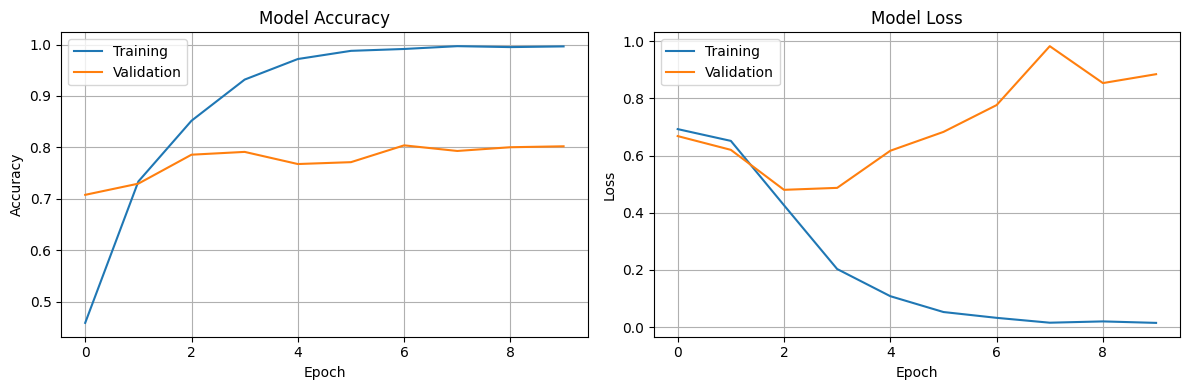

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
predicted_probabilities = model.predict(X_test, verbose=0)

y_predicted = (predicted_probabilities > 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_predicted)
precision = precision_score(y_test, y_predicted)
recall = recall_score(y_test, y_predicted)
f1 = f1_score(y_test, y_predicted)

print("Accuracy  :", round(accuracy, 3))
print("Precision :", round(precision, 3))
print("Recall    :", round(recall, 3))
print("F1 Score  :", round(f1, 3))

Accuracy  : 0.769
Precision : 0.838
Recall    : 0.81
F1 Score  : 0.824


In [18]:
# Predicting positive for every review would already score this much,
# so accuracy alone is not a useful measure here
print("Always positive baseline: %.3f" % y_test.mean())
print("Model accuracy          : %.3f" % accuracy)

Always positive baseline: 0.666
Model accuracy          : 0.769


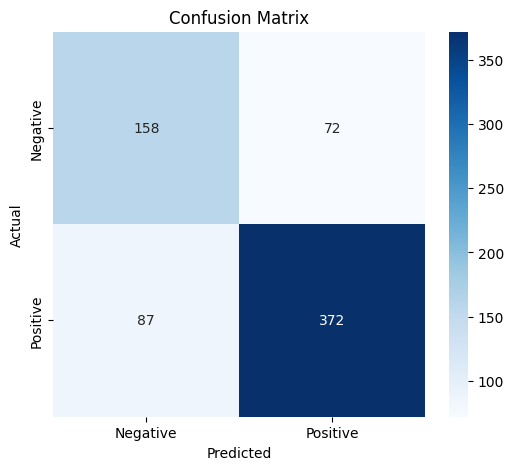

In [19]:
matrix = confusion_matrix(y_test, y_predicted)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [20]:
print(classification_report(
    y_test,
    y_predicted,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.64      0.69      0.67       230
    Positive       0.84      0.81      0.82       459

    accuracy                           0.77       689
   macro avg       0.74      0.75      0.74       689
weighted avg       0.77      0.77      0.77       689



In [21]:
sample = test_df.head(8).copy()

sample["Predicted"] = y_predicted[:8]
sample["Confidence"] = predicted_probabilities[:8].round(3)

for _, row in sample.iterrows():
    actual = "Positive" if row["sentiment"] == 1 else "Negative"
    predicted = "Positive" if row["Predicted"] == 1 else "Negative"

    print("Rating   :", row["rating"])
    print("Actual   :", actual)
    print("Predicted:", predicted, "(confidence %.3f)" % row["Confidence"])
    print("Review   :", row["text"][:160])
    print("-" * 70)

Rating   : 2.0
Actual   : Negative
Predicted: Negative (confidence 0.005)
Review   : Update. I went to a drive through car wash and to my surprise the car wash bent the front license plate all up. I removed it and straightened it back up and tri
----------------------------------------------------------------------
Rating   : 5.0
Actual   : Positive
Predicted: Positive (confidence 1.000)
Review   : I ordered this just to be on the safe side when hooking up at RV parks. It's always been a breeze to hook up and it's kept pressure to a reasonable level.
----------------------------------------------------------------------
Rating   : 5.0
Actual   : Positive
Predicted: Positive (confidence 1.000)
Review   : This is a solid, versatile lock that will fit Class II, Class III and Class IV hitch receivers.  Mine came with two hardened-steel chrome plated pins (not a sle
----------------------------------------------------------------------
Rating   : 5.0
Actual   : Positive
Predicted: Positive 

In [22]:
new_feedback = [
    "The brake pads were easy to fit and stopped the car smoothly.",
    "Terrible quality, the part broke within a week of driving.",
    "Excellent value for money and delivery was quick.",
    "The wipers leave streaks and do not clear the windscreen at all."
]

new_sequences = vectorizer(np.array(new_feedback)).numpy()

new_predictions = model.predict(new_sequences, verbose=0)

for text, score in zip(new_feedback, new_predictions.flatten()):
    label = "Positive" if score > 0.5 else "Negative"
    print("%s (%.3f)" % (label, score))
    print(text)
    print("-" * 70)

Positive (0.932)
The brake pads were easy to fit and stopped the car smoothly.
----------------------------------------------------------------------
Negative (0.000)
Terrible quality, the part broke within a week of driving.
----------------------------------------------------------------------
Positive (0.991)
Excellent value for money and delivery was quick.
----------------------------------------------------------------------
Negative (0.043)
The wipers leave streaks and do not clear the windscreen at all.
----------------------------------------------------------------------


In [23]:
print("SENTIMENT ANALYSIS - SUMMARY")
print("------------------------------")
print("Reviews analysed :", df.shape[0])
print("Training reviews :", train_df.shape[0])
print("Testing reviews  :", test_df.shape[0])
print("Vocabulary size  :", VOCABULARY_SIZE)
print("Sequence length  :", SEQUENCE_LENGTH)
print("Epochs           :", len(history.history["accuracy"]))
print("Accuracy         :", round(accuracy, 3))
print("Precision        :", round(precision, 3))
print("Recall           :", round(recall, 3))
print("F1 Score         :", round(f1, 3))

SENTIMENT ANALYSIS - SUMMARY
------------------------------
Reviews analysed : 3441
Training reviews : 2752
Testing reviews  : 689
Vocabulary size  : 10000
Sequence length  : 150
Epochs           : 10
Accuracy         : 0.769
Precision        : 0.838
Recall           : 0.81
F1 Score         : 0.824
